In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("energy_dataset.csv")
df.head()
# df.columns.tolist()

,time,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,...,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind offshore eday ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual
0,2015-01-01 00:00:00+01:00,447.0,329.0,0.0,4844.0,4821.0,162.0,0.0,0.0,0.0,...,196.0,0.0,6378.0,17.0,NaN,6436.0,26118.0,25385.0,50.10,65.41
1,2015-01-01 01:00:00+01:00,449.0,328.0,0.0,5196.0,4755.0,158.0,0.0,0.0,0.0,...,195.0,0.0,5890.0,16.0,NaN,5856.0,24934.0,24382.0,48.10,64.92
2,2015-01-01 02:00:00+01:00,448.0,323.0,0.0,4857.0,4581.0,157.0,0.0,0.0,0.0,...,196.0,0.0,5461.0,8.0,NaN,5454.0,23515.0,22734.0,47.33,64.48
3,2015-01-01 03:00:00+01:00,438.0,254.0,0.0,4314.0,4131.0,160.0,0.0,0.0,0.0,...,191.0,0.0,5238.0,2.0,NaN,5151.0,22642.0,21286.0,42.27,59.32
4,2015-01-01 04:00:00+01:00,428.0,187.0,0.0,4130.0,3840.0,156.0,0.0,0.0,0.0,...,189.0,0.0,4935.0,9.0,NaN,4861.0,21785.0,20264.0,38.41,56.04


In [3]:
df["time"] = pd.to_datetime(df["time"], utc=True)
df = df.set_index("time").sort_index()
print(df.index)

DatetimeIndex(['2014-12-31 23:00:00+00:00', '2015-01-01 00:00:00+00:00',
               '2015-01-01 01:00:00+00:00', '2015-01-01 02:00:00+00:00',
               '2015-01-01 03:00:00+00:00', '2015-01-01 04:00:00+00:00',
               '2015-01-01 05:00:00+00:00', '2015-01-01 06:00:00+00:00',
               '2015-01-01 07:00:00+00:00', '2015-01-01 08:00:00+00:00',
               ...
               '2018-12-31 13:00:00+00:00', '2018-12-31 14:00:00+00:00',
               '2018-12-31 15:00:00+00:00', '2018-12-31 16:00:00+00:00',
               '2018-12-31 17:00:00+00:00', '2018-12-31 18:00:00+00:00',
               '2018-12-31 19:00:00+00:00', '2018-12-31 20:00:00+00:00',
               '2018-12-31 21:00:00+00:00', '2018-12-31 22:00:00+00:00'],
              dtype='datetime64[ns, UTC]', name='time', length=35064, freq=None)


In [16]:
supply = df.filter(regex=r"^generation")
supply = supply.drop(columns="generation hydro pumped storage consumption")
active = (supply.notna() & supply.ne(0)).any()
supply = supply.loc[:, active]
supply.columns = supply.columns.str.removeprefix("generation ")
supply

,biomass,fossil brown coal/lignite,fossil gas,fossil hard coal,fossil oil,hydro run-of-river and poundage,hydro water reservoir,nuclear,other,other renewable,solar,waste,wind onshore
time,,,,,,,,,,,,,
2014-12-31 23:00:00+00:00,447.0,329.0,4844.0,4821.0,162.0,1051.0,1899.0,7096.0,43.0,73.0,49.0,196.0,6378.0
2015-01-01 00:00:00+00:00,449.0,328.0,5196.0,4755.0,158.0,1009.0,1658.0,7096.0,43.0,71.0,50.0,195.0,5890.0
2015-01-01 01:00:00+00:00,448.0,323.0,4857.0,4581.0,157.0,973.0,1371.0,7099.0,43.0,73.0,50.0,196.0,5461.0
2015-01-01 02:00:00+00:00,438.0,254.0,4314.0,4131.0,160.0,949.0,779.0,7098.0,43.0,75.0,50.0,191.0,5238.0
2015-01-01 03:00:00+00:00,428.0,187.0,4130.0,3840.0,156.0,953.0,720.0,7097.0,43.0,74.0,42.0,189.0,4935.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2018-12-31 18:00:00+00:00,297.0,0.0,7634.0,2628.0,178.0,1135.0,4836.0,6073.0,63.0,95.0,85.0,277.0,3113.0
2018-12-31 19:00:00+00:00,296.0,0.0,7241.0,2566.0,174.0,1172.0,3931.0,6074.0,62.0,95.0,33.0,280.0,3288.0
2018-12-31 20:00:00+00:00,292.0,0.0,7025.0,2422.0,168.0,1148.0,2831.0,6076.0,61.0,94.0,31.0,286.0,3503.0


In [5]:
supply_audit = pd.DataFrame({
    'recorded_values': supply.count(),
    'missing_values': supply.isna().sum(),
    'zero_values': supply.eq(0).sum()
})
display(supply_audit)

,recorded_values,missing_values,zero_values
biomass,35045,19,4
fossil brown coal/lignite,35046,18,10517
fossil gas,35046,18,1
fossil hard coal,35046,18,3
fossil oil,35045,19,3
hydro run-of-river and poundage,35045,19,3
hydro water reservoir,35046,18,3
nuclear,35047,17,3
other,35046,18,4
other renewable,35046,18,3


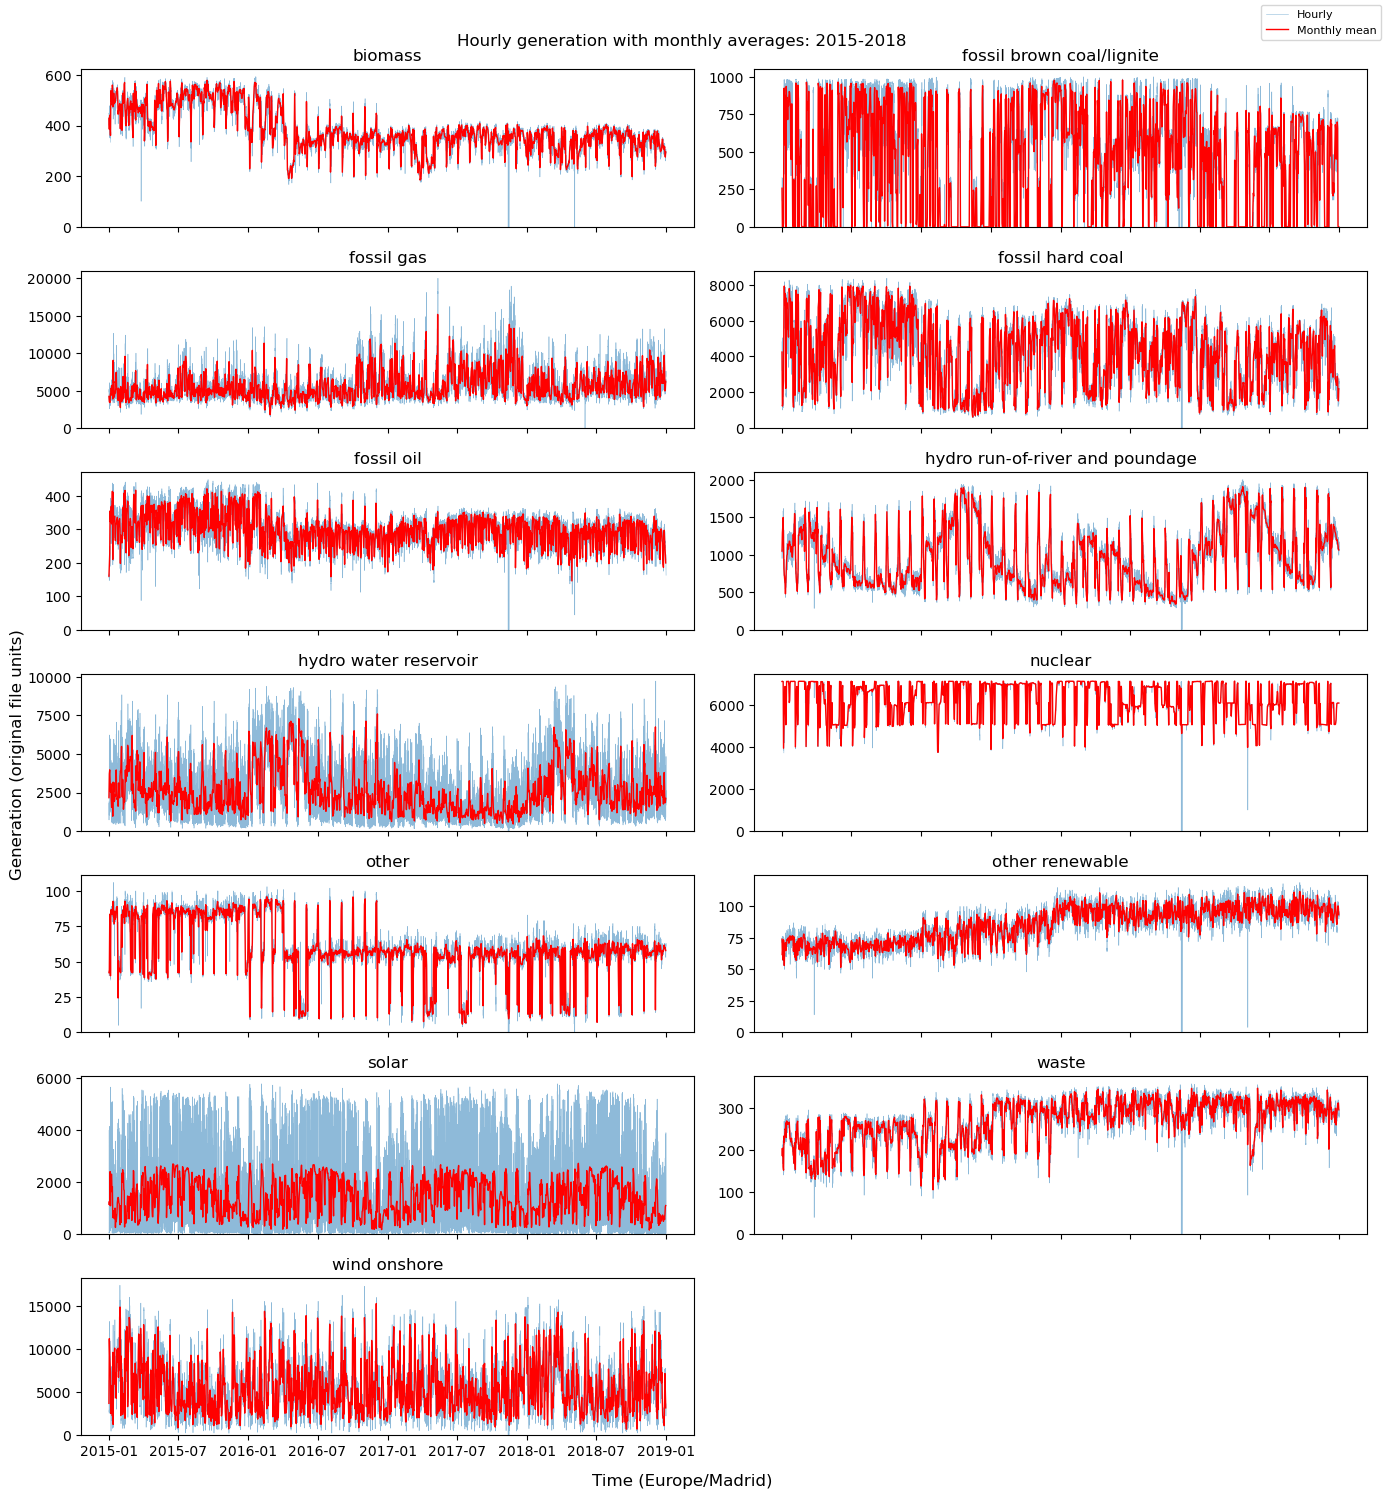

In [18]:
hourly_supply = supply.tz_convert("Europe/Madrid")
monthly_supply = hourly_supply.resample("MS").mean()
weekly_supply = hourly_supply.resample("W-MON", closed="left", label="left").mean()
daily_supply = hourly_supply.resample("D").mean()
n_columns = len(monthly_supply.columns)
n_rows = (n_columns + 1) // 2

fig, axes = plt.subplots(
    nrows=n_rows,
    ncols=2,
    figsize=(14, 15),
    sharex=True,
    sharey=False,
    squeeze=False
)

for ax, source in zip(axes.flat, daily_supply.columns):
    ax.plot(hourly_supply.index, hourly_supply[source], color="tab:blue", linewidth=0.4, alpha=0.5, label="Hourly", zorder=1)
    ax.plot(daily_supply.index, daily_supply[source], color="red", linewidth=1, label="Monthly mean", zorder=3)
    ax.set_title(source)
    ax.set_ylim(bottom=0)

for ax in axes.flat[n_columns:]:
    ax.set_visible(False)

fig.suptitle("Hourly generation with monthly averages: 2015-2018")
fig.legend(*axes.flat[0].get_legend_handles_labels(), loc="upper right", fontsize=8)
fig.supxlabel("Time (Europe/Madrid)")
fig.supylabel("Generation (original file units)")
fig.tight_layout()
plt.show()

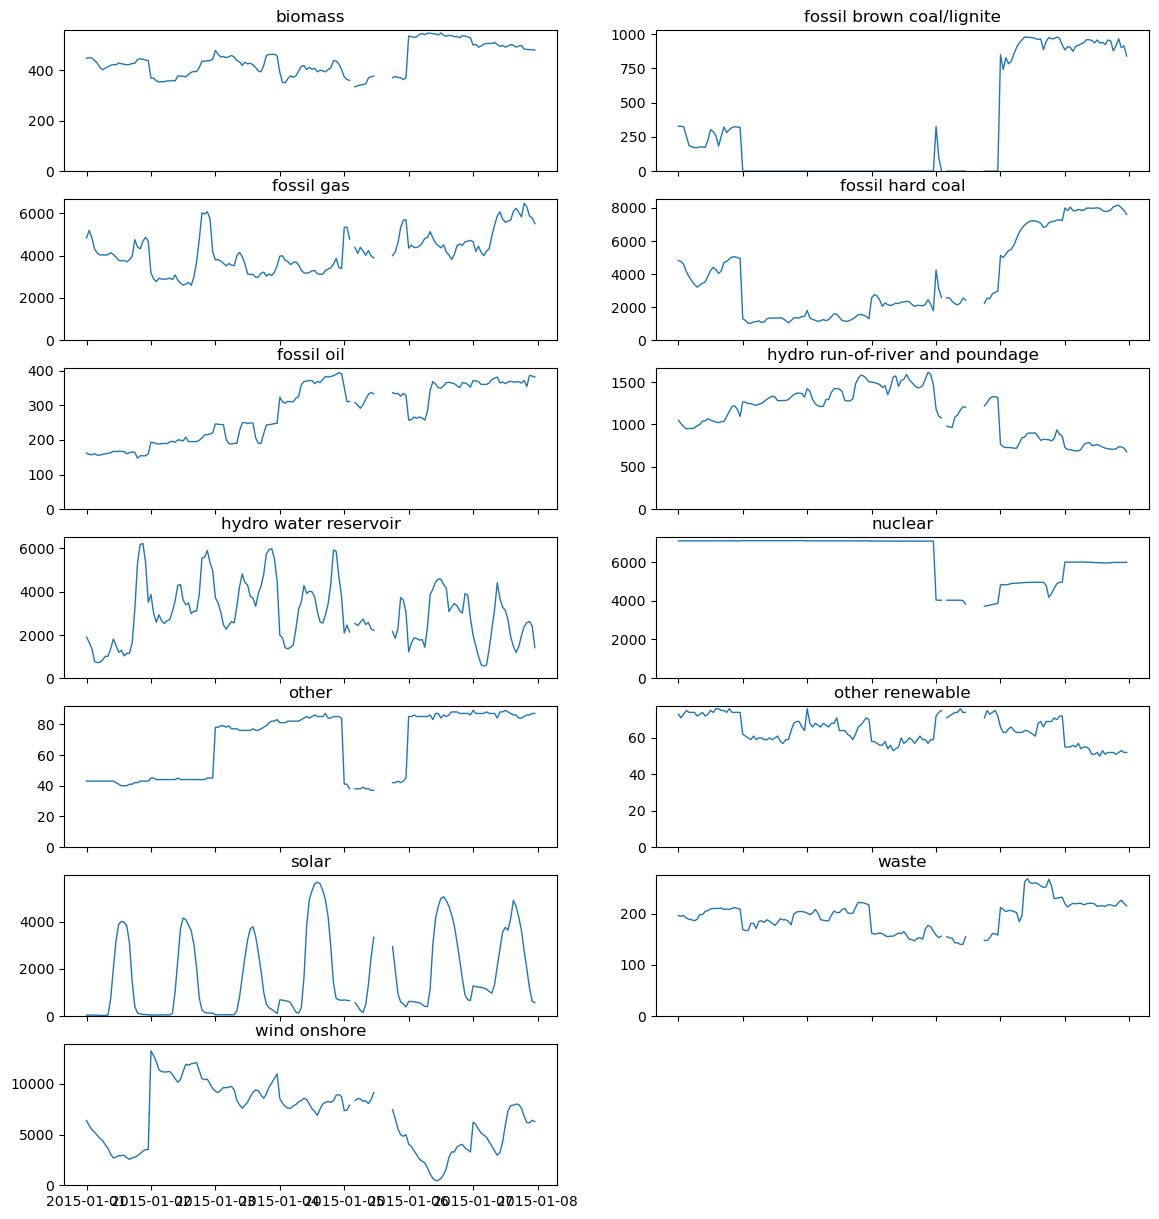

In [19]:
first_week = hourly_supply.iloc[:168]
zoom_fig, zoom_axes = plt.subplots(
    nrows=n_rows,
    ncols=2,
    figsize=(14, 15),
    sharex=True,
    sharey=False,
    squeeze=False
)

for ax, source in zip(zoom_axes.flat, first_week.columns):
    ax.plot(first_week.index, first_week[source], color="tab:blue", linewidth=1, label="Hourly", zorder=1)
    ax.set_title(source)
    ax.set_ylim(bottom=0)
    


for ax in zoom_axes.flat[n_columns:]:
    ax.set_visible(False)

fig.suptitle("Hourly generation with monthly averages: first week")
fig.legend(*axes.flat[0].get_legend_handles_labels(), loc="upper right", fontsize=8)
fig.supxlabel("Time (Europe/Madrid)")
fig.supylabel("Generation (original file units)")
fig.tight_layout()
plt.show()

/var/folders/4p/d5939nzx1cx141twsl1225j00000gn/T/ipykernel_8500/55072041.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


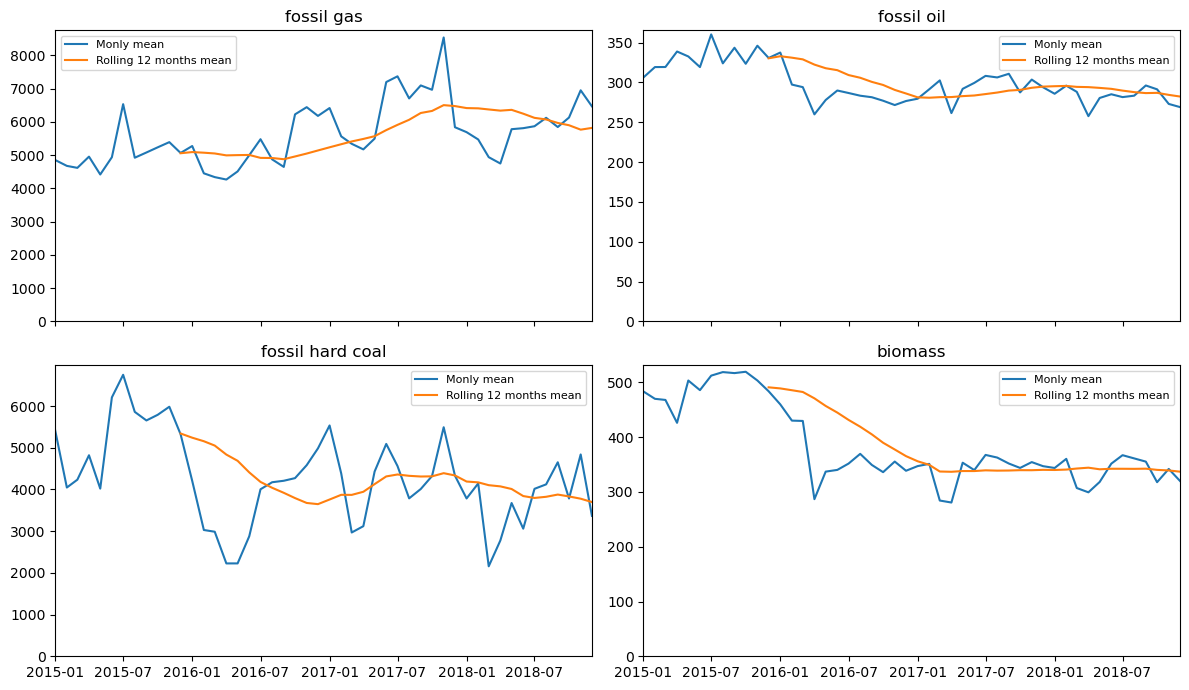

In [23]:
rolling_12_month = monthly_supply.rolling(window=12, min_periods=12).mean()
trend_sources = ['fossil gas', 'fossil oil', 'fossil hard coal', 'biomass']

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)

for ax, source in zip(axes.flat, trend_sources):
    ax.plot(monthly_supply.index, monthly_supply[source], color='tab:blue', label='Monly mean')
    ax.plot(monthly_supply.index, rolling_12_month[source], color='tab:orange', label='Rolling 12 months mean')

    ax.set_title(source)
    ax.set_ylim(bottom=0)
    ax.set_xlim(monthly_supply.index.min(), monthly_supply.index.max())
    ax.legend(fontsize=8)

fig.tight_layout()
fig.show()


In [35]:
hourly_mean = hourly_supply.groupby(hourly_supply.index.hour).mean()
weekly_mean = hourly_supply.groupby(hourly_supply.index.dayofweek).mean()

solar_hour_by_month = hourly_supply['solar'].groupby([hourly_supply.index.hour.rename('hour'), hourly_supply.index.month.rename('month')]).mean().unstack('month')

monthly_by_year = hourly_supply.groupby([hourly_supply.index.month.rename('month'), hourly_supply.index.year.rename('year')]).mean()
wind_monthly_by_year = monthly_by_year['wind onshore'].unstack('year')
wind_monthly_by_year

year,2015,2016,2017,2018
month,,,,
1,7587.697135,4993.399194,6483.298387,6197.444892
2,7731.806548,6534.337644,5330.943452,6864.555060
3,6747.878869,5884.690444,5623.149394,8771.240915
4,5506.381616,5343.191667,5741.669444,5289.247222
5,6757.408602,5309.384409,5031.903226,4389.743280
6,4375.495132,5638.537500,5586.527778,4779.433333
7,3955.254032,5715.833109,4799.477151,4059.907133
8,4856.173387,5103.193548,4348.514785,4358.579301
9,4323.800000,5484.695833,3883.879167,4265.988889


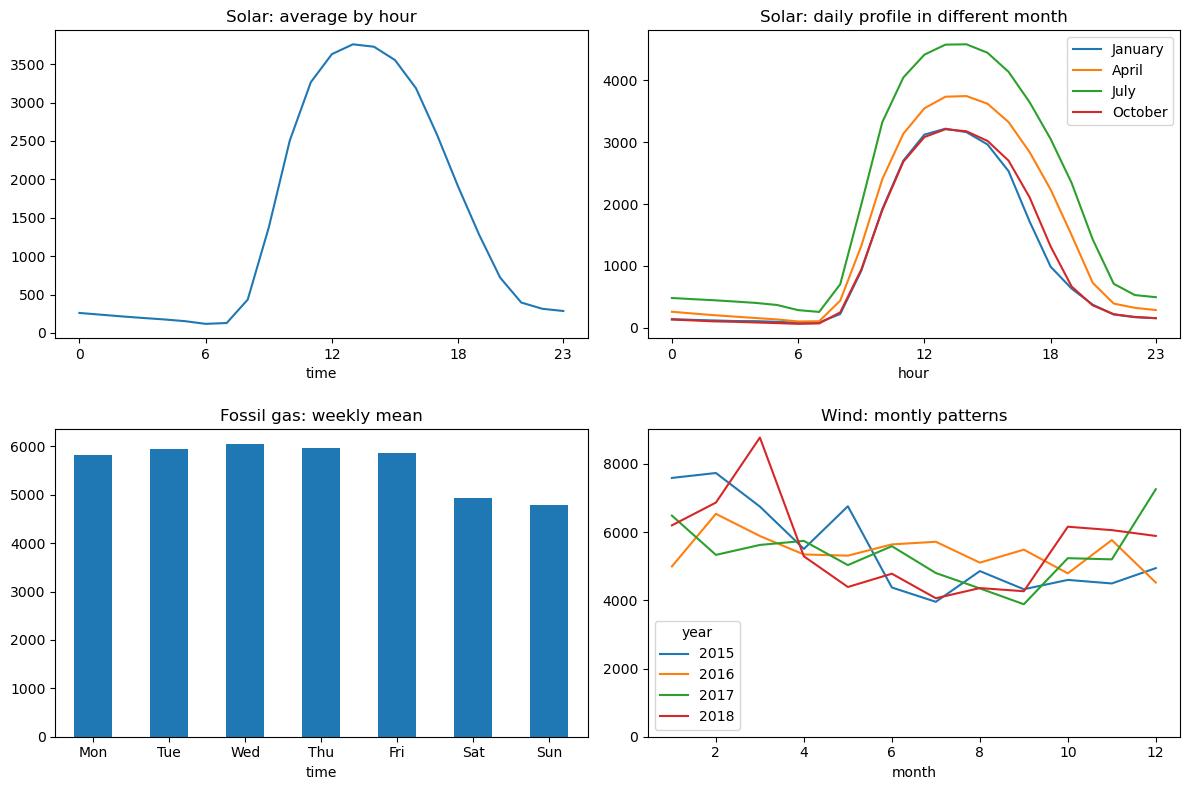

In [50]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

hourly_mean['solar'].plot(ax=axes[0, 0], color='tab:blue')
axes[0, 0].set_title('Solar: average by hour')
axes[0, 0].set_xticks([0, 6, 12, 18, 23])

selected_months = {1: 'January', 4: 'April', 7: 'July', 10: 'October'}
solar_hour_by_month[list(selected_months)].rename(columns=selected_months).plot(ax=axes[0, 1])
axes[0, 1].set_title('Solar: daily profile in different month')
axes[0, 1].set_xticks([0, 6, 12, 18, 23])
axes[0, 1].legend(fontsize=10)

weekly_mean['fossil gas'].plot.bar(ax=axes[1, 0], rot=0)
axes[1, 0].set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
axes[1, 0].set_title('Fossil gas: weekly mean')

wind_monthly_by_year.plot(ax=axes[1, 1])
axes[1, 1].set_title('Wind: montly patterns')
axes[1, 1].set_ylim(bottom=0)

fig.tight_layout(h_pad=2)
plt.show()


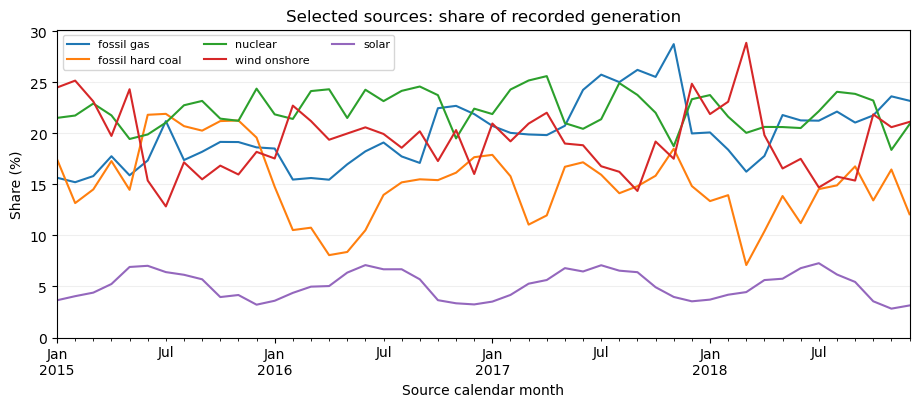

In [59]:
monthly_source_sum = hourly_supply.resample('MS').sum(min_count=1)
total_source_sum = monthly_source_sum.sum(axis=1)
monthly_source_share = monthly_source_sum.div(total_source_sum, axis=0).mul(100)

selected_sources = ['fossil gas', 'fossil hard coal', 'nuclear', 'wind onshore', 'solar']
ax = monthly_source_share[selected_sources].plot(figsize=(11, 4))
ax.set_title('Selected sources: share of recorded generation')
ax.set_xlabel('Source calendar month')
ax.set_ylabel('Share (%)')
ax.set_ylim(bottom=0)
ax.legend(fontsize=8, ncol=3)
ax.grid(axis='y', alpha=0.2)

In [62]:
hourly_changes = hourly_supply.diff()
variability = pd.DataFrame({
    'mean': hourly_supply.mean(),
    'std': hourly_supply.std(),
    'largest chage': abs(hourly_changes).max()
})
display(variability.round(1))

,mean,std,largest chage
biomass,383.5,85.4,379.0
fossil brown coal/lignite,448.1,354.6,984.0
fossil gas,5622.7,2201.8,11504.0
fossil hard coal,4256.1,1961.6,7056.0
fossil oil,298.3,52.5,359.0
hydro run-of-river and poundage,972.1,400.8,1374.0
hydro water reservoir,2605.1,1835.2,5322.0
nuclear,6263.9,839.7,7089.0
other,60.2,20.2,77.0
other renewable,85.6,14.1,107.0
